# P1 baseline — S0 Buy & Hold, $900, 2026 Q1–Q3

Buy once with all $900 at the open of the first available 1D bar of 2026, then hold to the last close of Q3.
Top panel is the same candles as `plot-1d-ohlc.ipynb`; bottom panel is the position's USD value at each close.

- Gross only: no fees, spread, funding or QQQ dividends yet.
- **XAUT** uses MT5 **XAUUSD** spot gold as a stand-in.

In [1]:
from helpers.replayer_bars import DATA_SYMBOL, period_bars
from helpers.passive_benchmarks import CAPITAL, plot_buy_hold, simulate

SYMBOLS = ["BTC", "ETH", "XAUT", "QQQ"]
TIMEFRAME, START, END = "1d", "2026Q1", "2026Q3"
LABEL = "2026 Q1–Q3"

bars = {symbol: period_bars(symbol, TIMEFRAME, START, END) for symbol in SYMBOLS}
for symbol, price in bars.items():
    entry, value = price["open"].iloc[0], simulate(price)["buy_hold"]
    print(f"{symbol:<5} buy {price.index[0]:%Y-%m-%d} @ {entry:>10,.2f} -> {CAPITAL / entry:.6g} units | "
          f"{price.index[-1]:%Y-%m-%d} worth ${value.iloc[-1]:,.2f} ({value.iloc[-1] / CAPITAL - 1:+.1%}), low ${value.min():,.2f}")

BTC   buy 2026-01-01 @  87,643.30 -> 0.0102689 units | 2026-09-30 worth $858.65 (-4.6%), low $602.08
ETH   buy 2026-01-01 @   2,971.58 -> 0.302869 units | 2026-09-30 worth $813.39 (-9.6%), low $474.82
XAUT  buy 2026-01-02 @   4,318.21 -> 0.20842 units | 2026-09-30 worth $866.40 (-3.7%), low $828.79
QQQ   buy 2026-01-02 @     620.57 -> 1.45028 units | 2026-09-30 worth $1,077.24 (+19.7%), low $806.40


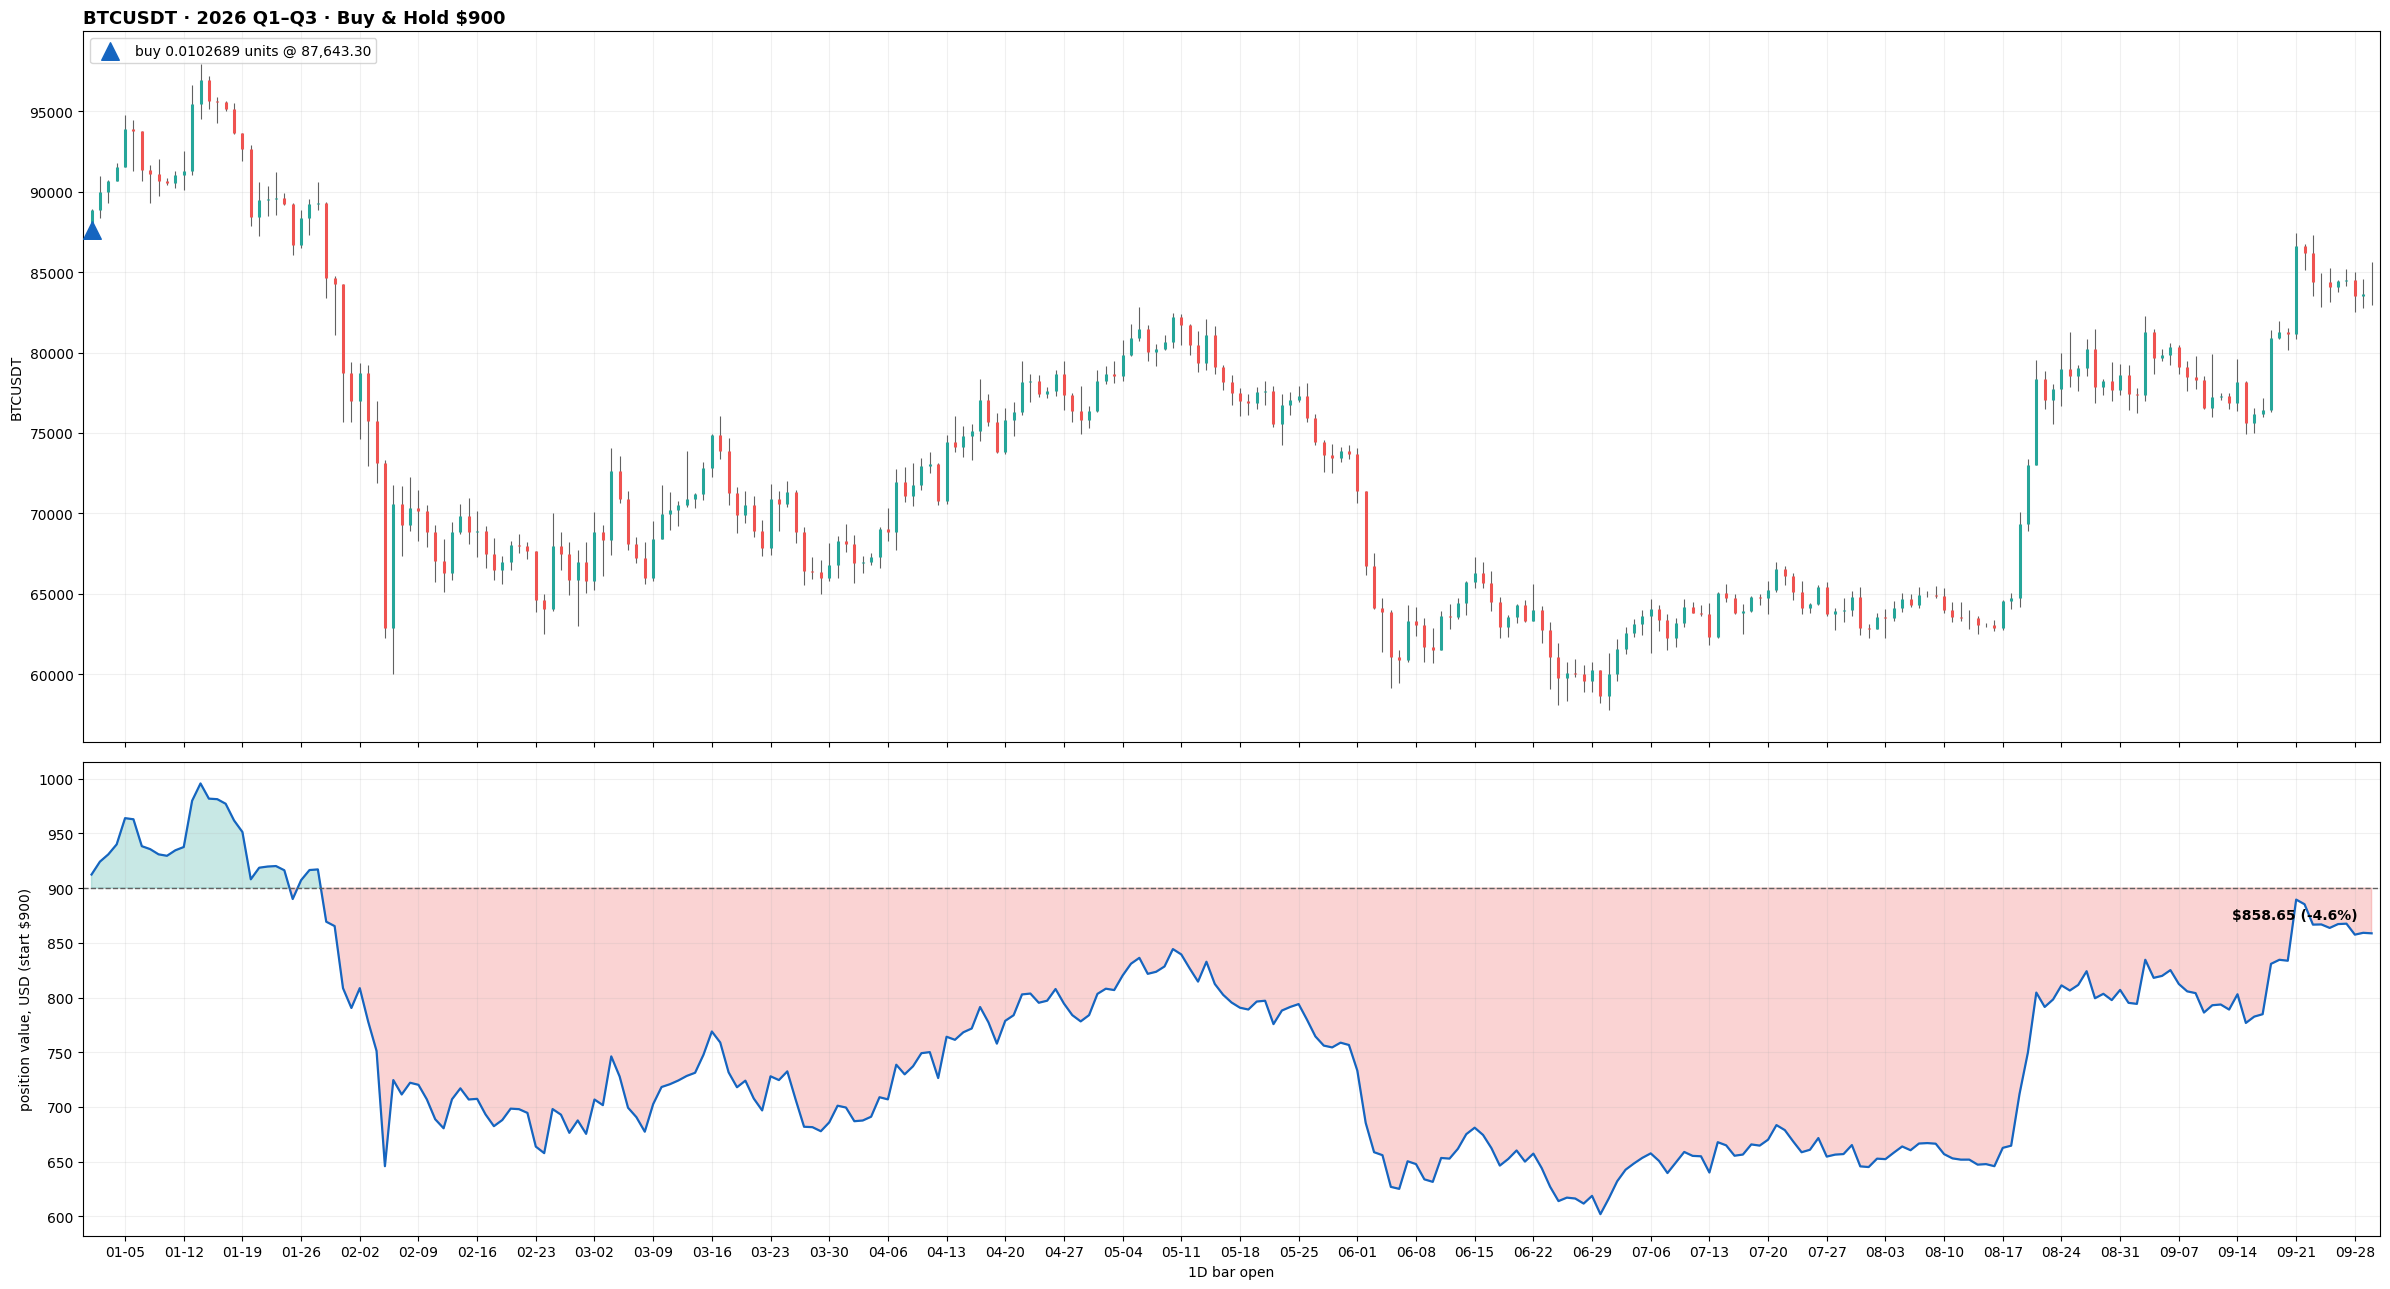

In [2]:
plot_buy_hold(bars["BTC"], f"BTCUSDT · {LABEL} · Buy & Hold ${CAPITAL:,.0f}", "BTCUSDT")

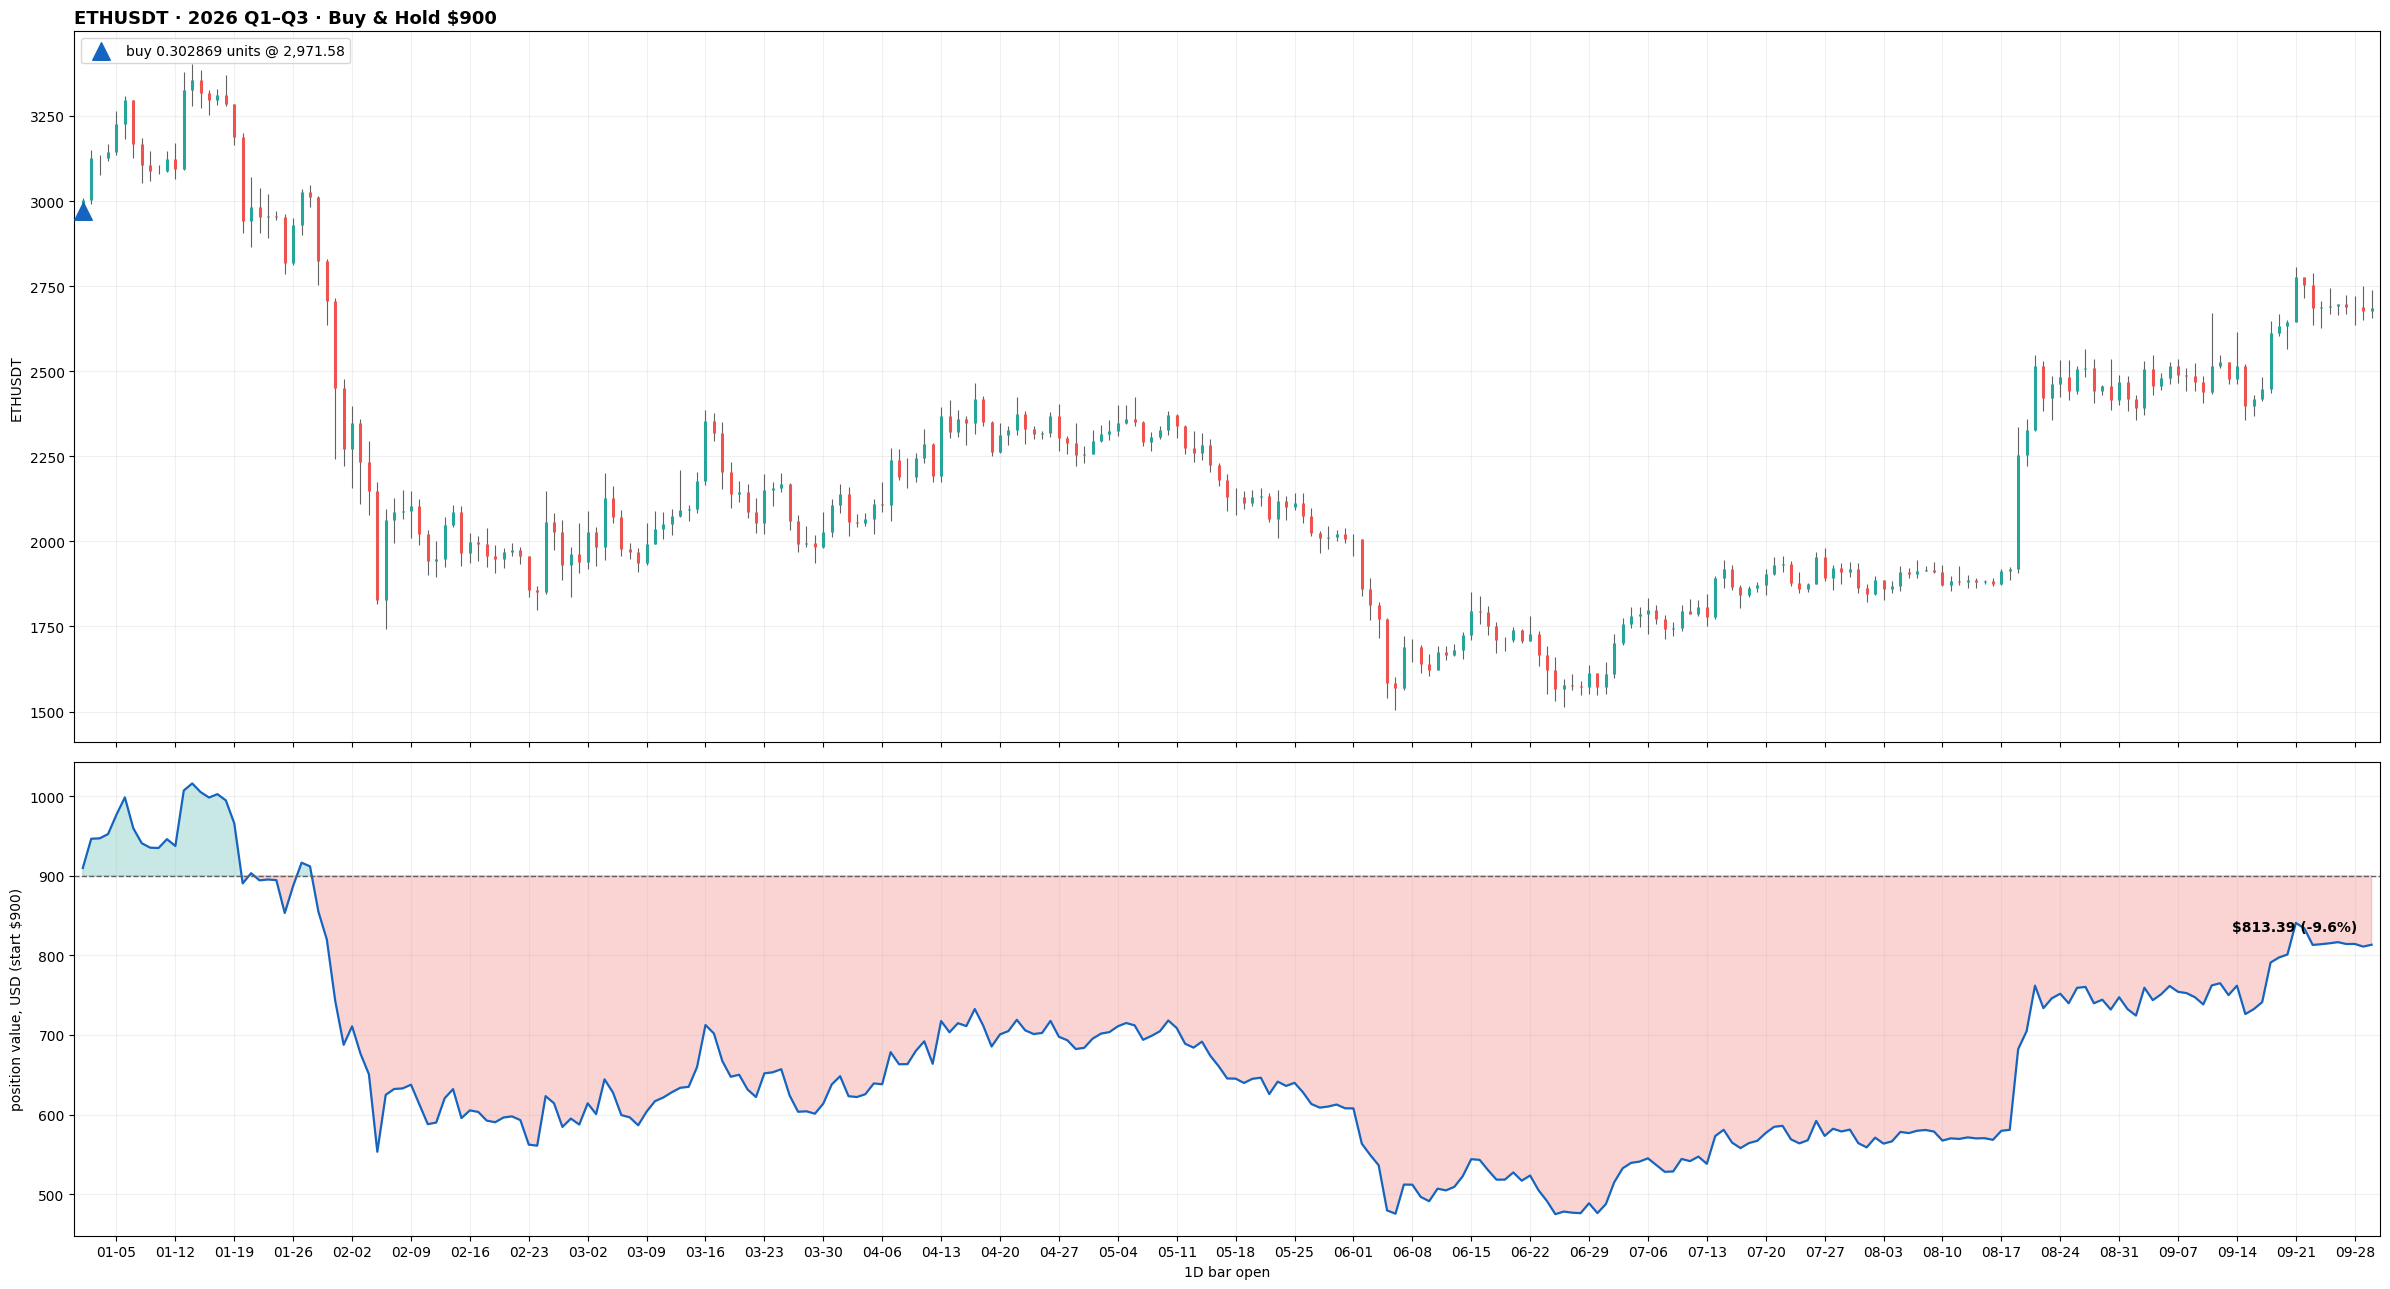

In [3]:
plot_buy_hold(bars["ETH"], f"ETHUSDT · {LABEL} · Buy & Hold ${CAPITAL:,.0f}", "ETHUSDT")

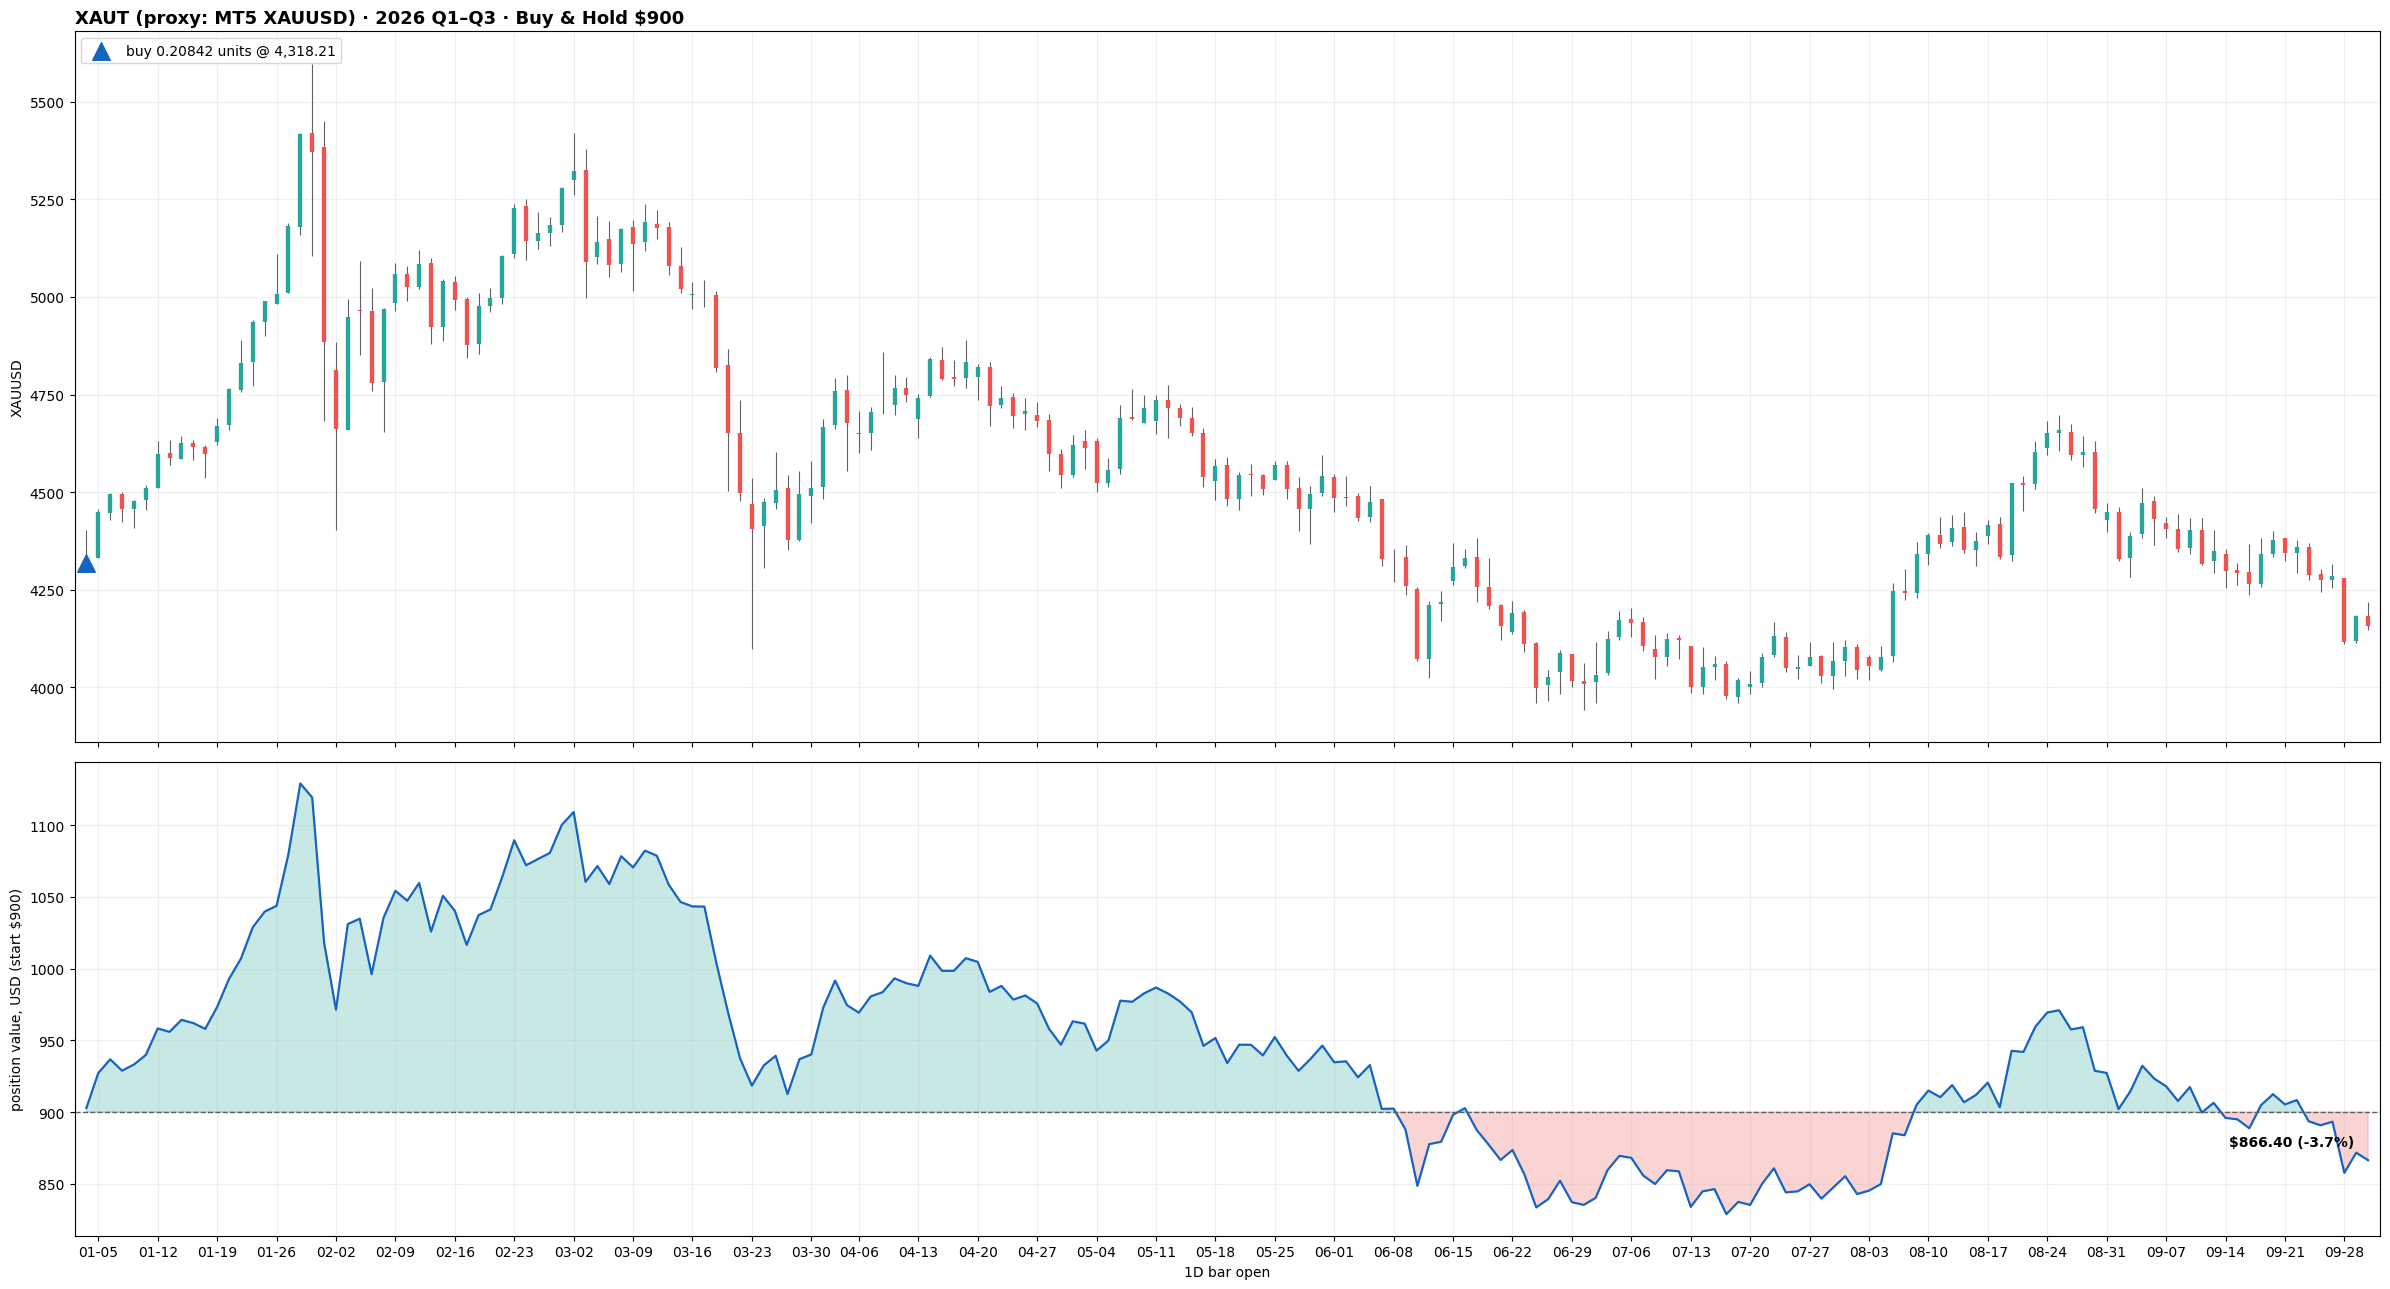

In [4]:
plot_buy_hold(bars["XAUT"], f"XAUT (proxy: MT5 XAUUSD) · {LABEL} · Buy & Hold ${CAPITAL:,.0f}", "XAUUSD")

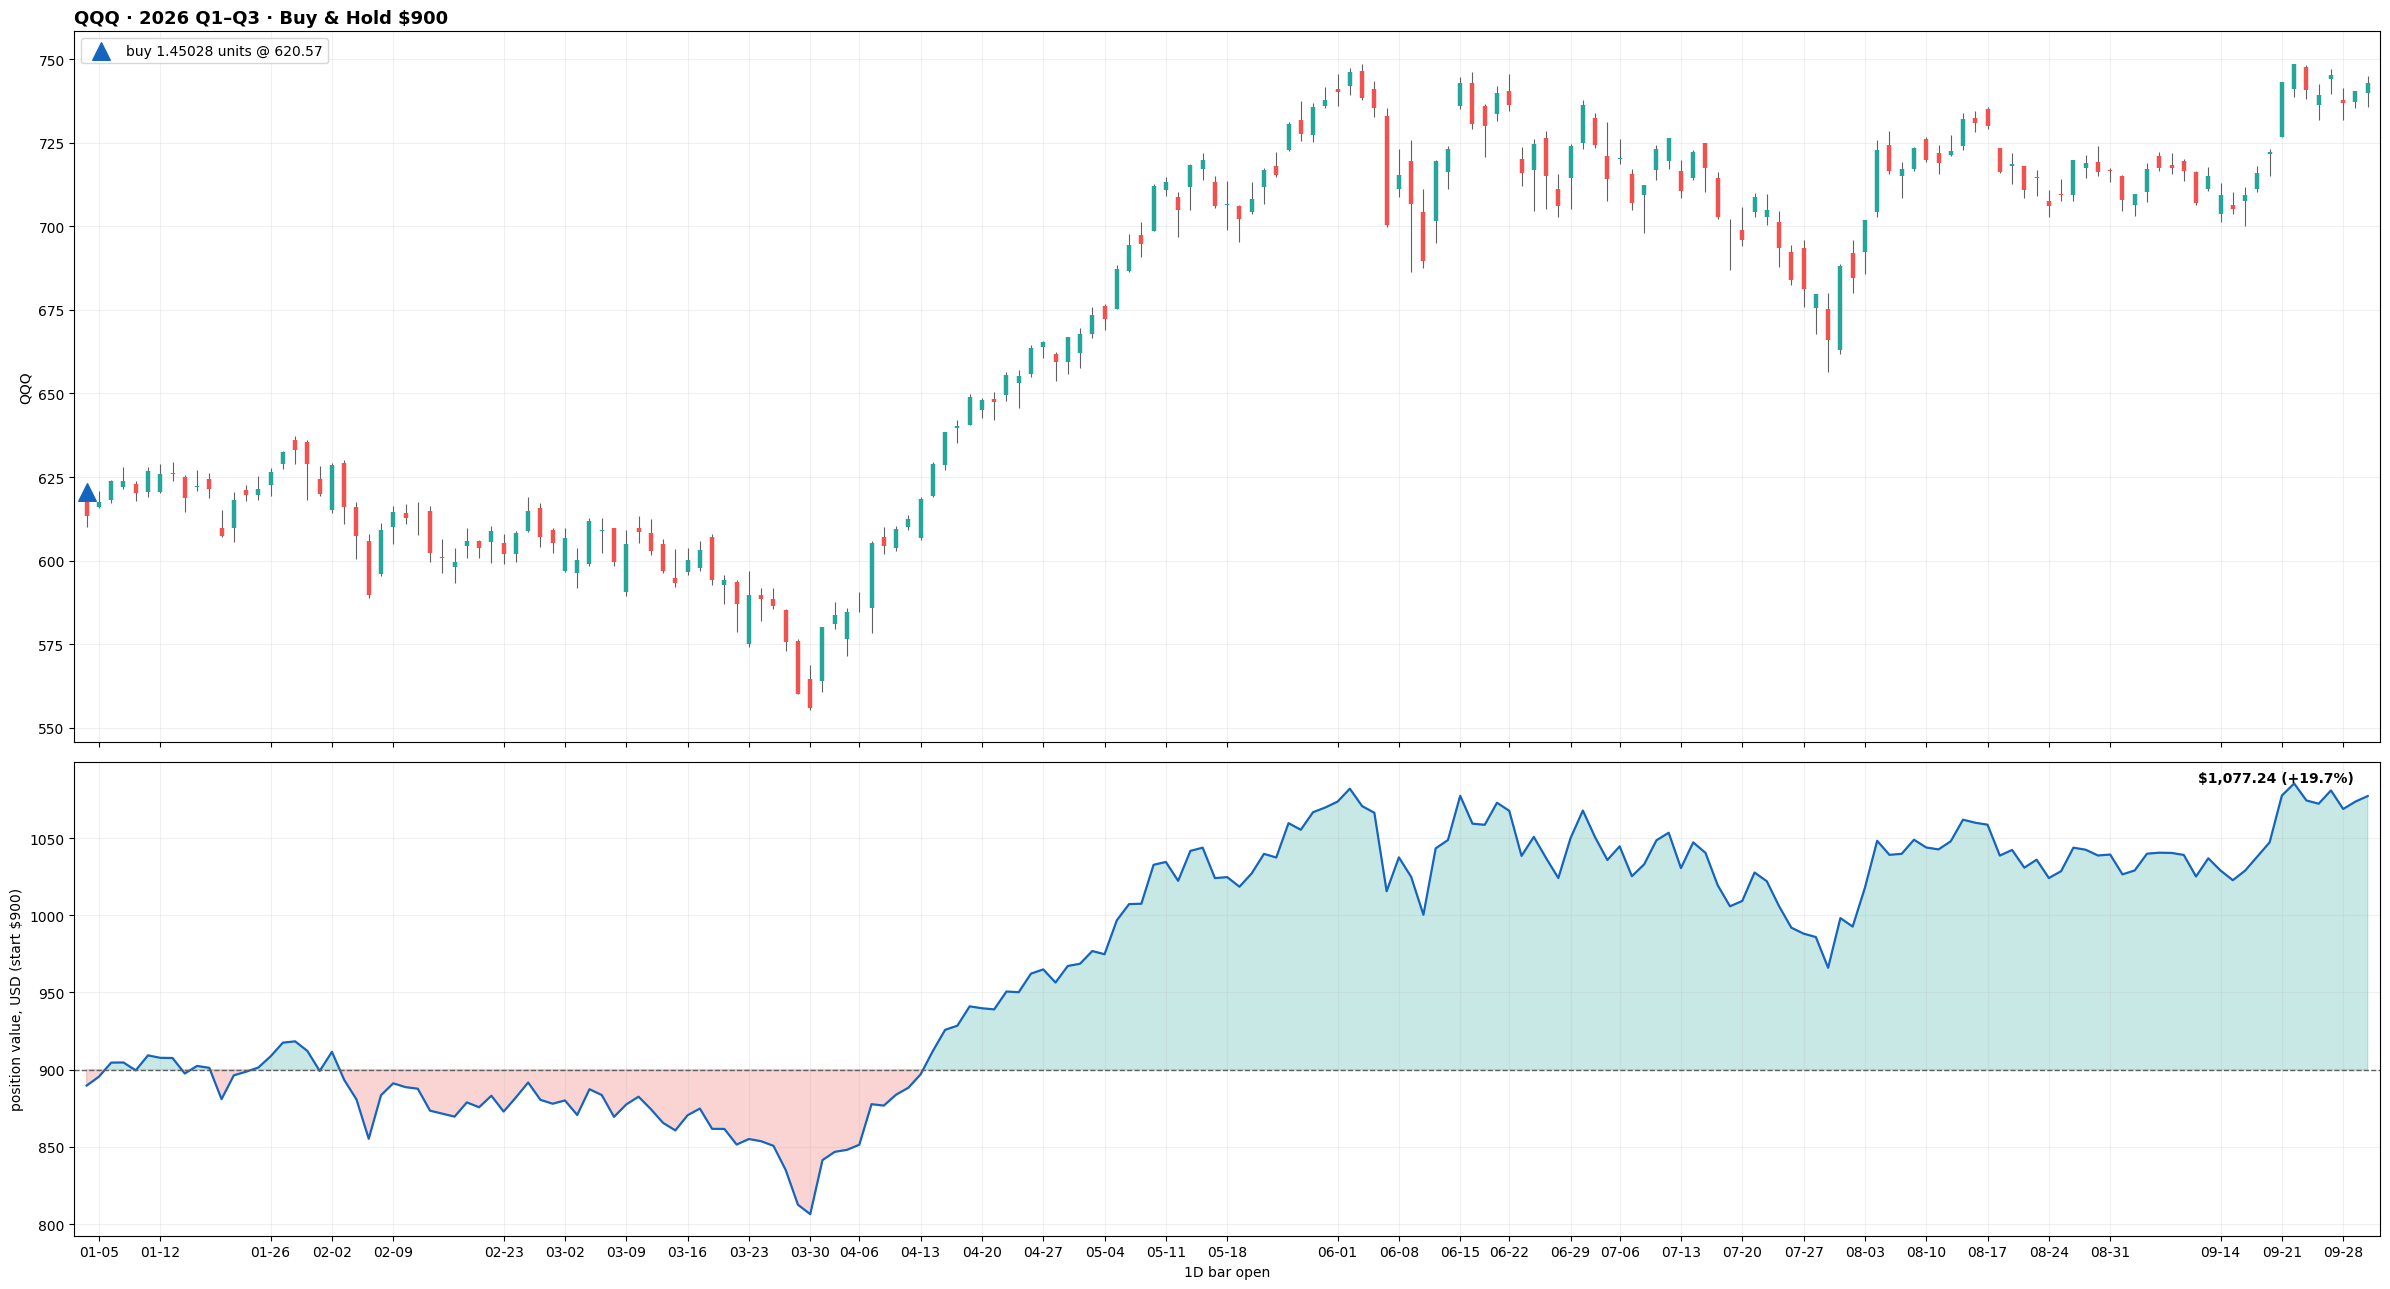

In [5]:
plot_buy_hold(bars["QQQ"], f"QQQ · {LABEL} · Buy & Hold ${CAPITAL:,.0f}", "QQQ")